# FIREWATCH AI — Stage 11: Validation reference and coverage readiness

**Date:** 2026-11-14  
**Purpose:** assess source-native fields and identify official reference products for a defensible association validation plan. This stage is a documentation and readiness audit; it does not download or label any new observations.

## Actual source fields

Across the extracted files, `scan` and `track` are present for all rows. NASA FIRMS documents these as actual along-scan and along-track pixel dimensions (km), varying with scan geometry. This is useful for a pixel-scale-aware sensitivity analysis, although orientation/footprint polygon is not present in the delivered CSV. The `type` field is absent from all NRT rows and available in archive rows. Archive `type` is algorithm-inferred categorization, not independent truth. VIIRS monthly `Type` history has known production-version caveats; the row `version` field and current per-file README do not expose enough processing detail to certify the exact monthly file revision. Keep it as source evidence only.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
obs=pd.read_parquet(ROOT/'data'/'processed'/'observations.parquet',columns=['year_folder','product_code','stream_type','satellite','scan_num','track_num','type','type_num','daynight','confidence','confidence_family'])
source=(obs.groupby(['year_folder','product_code','stream_type','satellite'],dropna=False)
 .agg(rows=('scan_num','size'),scan_missing=('scan_num',lambda s:int(s.isna().sum())),track_missing=('track_num',lambda s:int(s.isna().sum())),
      scan_median_km=('scan_num','median'),scan_p95_km=('scan_num',lambda s:s.quantile(.95)),
      track_median_km=('track_num','median'),track_p95_km=('track_num',lambda s:s.quantile(.95)),type_present=('type_num',lambda s:int(s.notna().sum())))
 .reset_index())
display(source.round(3))
print('Totals:',len(obs),'rows; scan missing',int(obs.scan_num.isna().sum()),'; track missing',int(obs.track_num.isna().sum()),'; type missing',int(obs.type_num.isna().sum()))


,year_folder,product_code,stream_type,satellite,rows,scan_missing,track_missing,scan_median_km,scan_p95_km,track_median_km,track_p95_km,type_present
0,2025,J1V-C2,archive,N20,224606,0.0,0.0,0.43,0.6,0.43,0.68,224606.0
1,2025,J2V-C2,archive,N21,218188,0.0,0.0,0.43,0.61,0.44,0.69,218188.0
2,2025,M-C61,archive,Aqua,35900,0.0,0.0,1.2,2.8,1.1,1.6,35900.0
3,2025,M-C61,archive,Terra,6220,0.0,0.0,1.2,2.8,1.1,1.6,6220.0
4,2025,SV-C2,archive,SNPP,227320,0.0,0.0,0.43,0.6,0.42,0.68,227320.0
5,2026,J1V-C2,archive,N20,132632,0.0,0.0,0.43,0.6,0.42,0.67,132632.0
6,2026,J1V-C2,near_real_time,N20,3640,0.0,0.0,0.42,0.57,0.42,0.64,0.0
7,2026,J2V-C2,archive,N21,126367,0.0,0.0,0.43,0.61,0.44,0.7,126367.0
8,2026,J2V-C2,near_real_time,N21,3332,0.0,0.0,0.44,0.61,0.47,0.7,0.0
9,2026,M-C61,archive,Aqua,15938,0.0,0.0,1.1,2.6,1.1,1.6,15938.0


Totals: 1130027 rows; scan missing 0 ; track missing 0 ; type missing 10938


In [2]:
typed=obs.assign(type_value=obs.type.astype('string').fillna('<not supplied>'))
display(typed.groupby(['product_code','stream_type','type_value'],dropna=False).size().rename('records').reset_index())
display(obs.groupby(['product_code','stream_type','daynight'],dropna=False).size().rename('records').reset_index())
display(obs.groupby(['product_code','stream_type','confidence_family','confidence'],dropna=False).size().rename('records').reset_index().head(40))


,product_code,stream_type,type_value,records
0,J1V-C2,archive,0,356023
1,J1V-C2,archive,2,932
2,J1V-C2,archive,3,283
3,J1V-C2,near_real_time,<not supplied>,3640
4,J2V-C2,archive,0,343415
5,J2V-C2,archive,2,928
6,J2V-C2,archive,3,212
7,J2V-C2,near_real_time,<not supplied>,3332
8,M-C61,archive,0,60782
9,M-C61,archive,1,35


,product_code,stream_type,daynight,records
0,J1V-C2,archive,D,302313
1,J1V-C2,archive,N,54925
2,J1V-C2,near_real_time,D,3474
3,J1V-C2,near_real_time,N,166
4,J2V-C2,archive,D,291265
5,J2V-C2,archive,N,53290
6,J2V-C2,near_real_time,D,3149
7,J2V-C2,near_real_time,N,183
8,M-C61,archive,D,56291
9,M-C61,archive,N,4674


,product_code,stream_type,confidence_family,confidence,records
0,J1V-C2,archive,categorical,h,11085
1,J1V-C2,archive,categorical,l,62338
2,J1V-C2,archive,categorical,n,283815
3,J1V-C2,near_real_time,categorical,h,144
4,J1V-C2,near_real_time,categorical,l,875
5,J1V-C2,near_real_time,categorical,n,2621
6,J2V-C2,archive,categorical,h,15203
7,J2V-C2,archive,categorical,l,56981
8,J2V-C2,archive,categorical,n,272371
9,J2V-C2,near_real_time,categorical,h,186


C:\Users\ngong\AppData\Local\Temp\ipykernel_50448\377816719.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([x.scan_num.dropna().astype(float) for x in samples],labels=platforms,showfliers=False); axes[0].set_title('Along-scan pixel dimension'); axes[0].set_ylabel('km')
C:\Users\ngong\AppData\Local\Temp\ipykernel_50448\377816719.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([x.track_num.dropna().astype(float) for x in samples],labels=platforms,showfliers=False); axes[1].set_title('Along-track pixel dimension'); axes[1].set_ylabel('km')


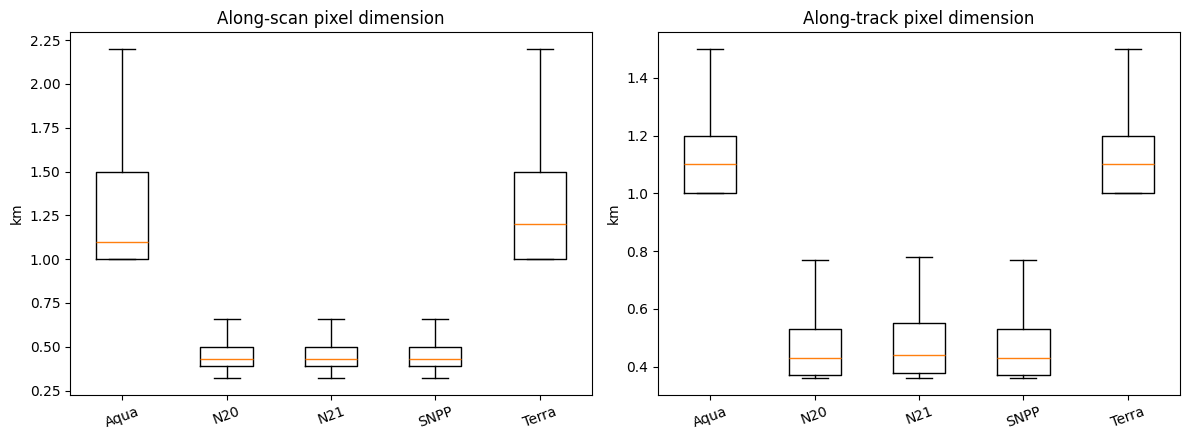

In [3]:
rng=np.random.default_rng(20261114); platforms=sorted(obs.satellite.dropna().unique()); samples=[]
for platform in platforms:
    group=obs.loc[obs.satellite.eq(platform),['scan_num','track_num']]
    if len(group)>20000: group=group.iloc[rng.choice(len(group),20000,replace=False)]
    samples.append(group)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].boxplot([x.scan_num.dropna().astype(float) for x in samples],labels=platforms,showfliers=False); axes[0].set_title('Along-scan pixel dimension'); axes[0].set_ylabel('km')
axes[1].boxplot([x.track_num.dropna().astype(float) for x in samples],labels=platforms,showfliers=False); axes[1].set_title('Along-track pixel dimension'); axes[1].set_ylabel('km')
for ax in axes: ax.tick_params(axis='x',rotation=20)
fig.tight_layout(); plt.show()


## Catalog availability snapshot

A read-only NASA CMR granule search was made for 2025-10-01 through 2025-10-31 over the dashboard’s broad box (west=8, south=1, east=17, north=14). It returned candidate Level-2 swath granules for Terra MODIS (`MOD14`, 061), Aqua MODIS (`MYD14`, 061), and VIIRS (`VNP14IMG`, `VJ114IMG`, `VJ214IMG`, 002). CMR result records may include reprocessing versions; the NOAA-21 search returned 172 metadata entries representing 160 unique acquisition IDs after removing the processing timestamp suffix. A granule bounding-box intersection is not proof that every pixel in Cameroon was validly observed.

[Query the NASA CMR granule catalog](https://cmr.earthdata.nasa.gov/search/granules.json?short_name=VNP14IMG&version=002&temporal=2025-10-01T00%3A00%3A00Z%2C2025-10-31T23%3A59%3A59Z&bounding_box=8%2C1%2C17%2C14&page_size=2000).

NASA VIIRS C2 swaths include per-pixel fire-mask classes and algorithm QA; MODIS L2 swaths also include fire masks and quality data. These offer a route to reconstruct sensor observation opportunities and compare detections only where data were actually processed. Earthdata-authenticated granule downloads and implementation are separate follow-up work.


## Recommended validation ladder

1. Start with a manageable, mature archive month (October 2025). Obtain the relevant MOD14/MYD14 and three VIIRS L2 swaths; build a manifest of granule acquisition/processing IDs and verify source coverage before analysis.
2. Match FIRMS CSV detections to the source granule fire pixels using UTC time, geolocation, platform, and product-specific indexing where available. Retain join distance and source granule ID.
3. Derive per-source observation opportunity masks from pixel geolocation, fire masks, and QA. Separate valid non-fire land, fire, cloud, water, glint, bow-tie-deleted, and unprocessed/invalid pixels as product documentation supports. Align mask footprints and time windows explicitly.
4. Re-evaluate false-association nulls only over common valid observation opportunities. Keep model outputs as pairwise evidence and publish unmatched/unknown-coverage cases.
5. Seek independent temporal corroboration from EUMETSAT LSA SAF SEVIRI/MSG FRP-PIXEL (Africa, ~3 km, 15 min) for historical fire persistence. It has different pixel scale/algorithm and is corroboration, not truth. Monthly burned-area products can corroborate later burn scars only at monthly/landscape scales, with QA/unmapped fractions respected.

## Constraints

CMR catalog metadata is public, but no Level-2 files were downloaded in this stage; data access may require Earthdata Login. No field-report/perimeter labels were found in the supplied workspace. The NVIDIA GPU is unnecessary for CSV schema review, geospatial matching, or an October swath-mask pilot; I/O and geolocation processing dominate at this scale. Do not run a learned model until the independent reference/coverage layer is in place.
